In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
RANDOM_STATE = 42


In [2]:
tx  = pd.read_csv('C:\\Users\\admin\\Desktop\\M2 thesis\\ieee-fraud-detection\\train_transaction.csv')
idn = pd.read_csv('C:\\Users\\admin\\Desktop\\M2 thesis\\ieee-fraud-detection\\train_identity.csv')
df = tx.merge(idn, how="left", on="TransactionID")
del tx, idn
print(f"Merged shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Merged shape: 590,540 rows x 434 columns


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [3]:
print(df.shape)

df.info()

df.describe().T

(590540, 434)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), object(31)
memory usage: 1.9+ GB


,count,mean,std,min,25%,50%,75%,max
TransactionID,590540.0,3.282270e+06,1.704744e+05,2987000.000,3134634.750,3282269.500,3429904.25,3.577539e+06
isFraud,590540.0,3.499001e-02,1.837546e-01,0.000,0.000,0.000,0.00,1.000000e+00
TransactionDT,590540.0,7.372311e+06,4.617224e+06,86400.000,3027057.750,7306527.500,11246620.00,1.581113e+07
TransactionAmt,590540.0,1.350272e+02,2.391625e+02,0.251,43.321,68.769,125.00,3.193739e+04
card1,590540.0,9.898735e+03,4.901170e+03,1000.000,6019.000,9678.000,14184.00,1.839600e+04
...,...,...,...,...,...,...,...,...
id_22,5169.0,1.600271e+01,6.897665e+00,10.000,14.000,14.000,14.00,4.400000e+01
id_24,4747.0,1.280093e+01,2.372447e+00,11.000,11.000,11.000,15.00,2.600000e+01
id_25,5132.0,3.296089e+02,9.746109e+01,100.000,321.000,321.000,371.00,5.480000e+02
id_26,5163.0,1.490703e+02,3.210199e+01,100.000,119.000,149.000,169.00,2.160000e+02


In [4]:
df["isFraud"].value_counts()

df["isFraud"].value_counts(normalize=True)

isFraud
0    0.96501
1    0.03499
Name: proportion, dtype: float64

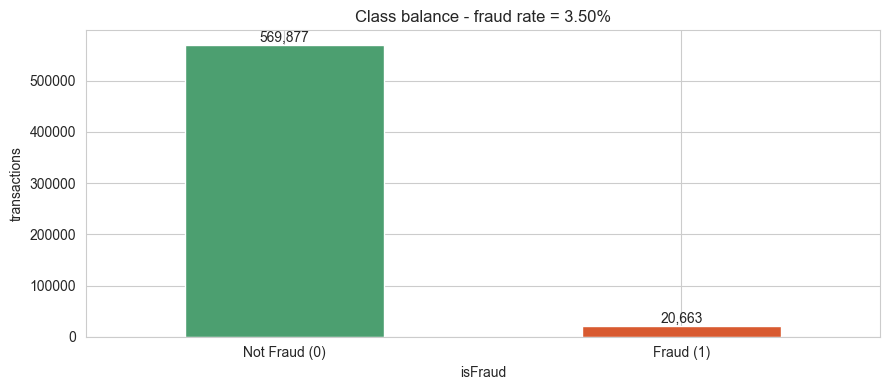

Fraud is 3.50% of transactions -> highly imbalanced


In [5]:
rate = df["isFraud"].mean()
ax = df["isFraud"].value_counts().plot(kind="bar", color=["#4C9F70", "#D85A30"])
ax.set_xticklabels(["Not Fraud (0)", "Fraud (1)"], rotation=0)
ax.set_title(f"Class balance - fraud rate = {rate:.2%}")
ax.set_ylabel("transactions")
for i, v in enumerate(df["isFraud"].value_counts()):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()
print(f"Fraud is {rate:.2%} of transactions -> highly imbalanced")

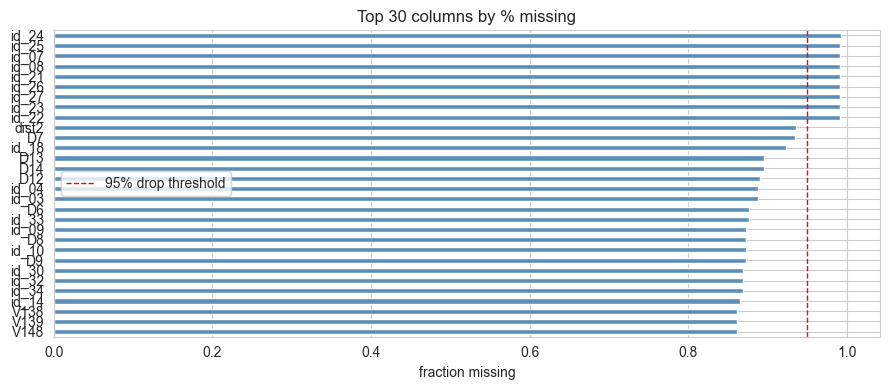

Columns >95% missing: 9


In [6]:
miss = df.isna().mean().sort_values(ascending=False)
top = miss.head(30)
ax = top.plot(kind="barh", color="#5B8FB9")
ax.invert_yaxis()
ax.set_title("Top 30 columns by % missing")
ax.set_xlabel("fraction missing")
plt.axvline(0.95, color="red", ls="--", lw=1, label="95% drop threshold")
plt.legend(); plt.tight_layout(); plt.show()
print(f"Columns >95% missing: {(miss > 0.95).sum()}")

In [5]:
num_cols = df.select_dtypes(include=["number"]).columns

cat_cols = df.select_dtypes(include=["object","category"]).columns

In [8]:
num_cols

Index(['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'card1',
       'card2', 'card3', 'card5', 'addr1', 'addr2',
       ...
       'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_24', 'id_25',
       'id_26', 'id_32'],
      dtype='object', length=403)

In [9]:
cat_cols

Index(['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1',
       'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15',
       'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33',
       'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType',
       'DeviceInfo'],
      dtype='object')

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
duplicates = df[df.drop(columns=["TransactionID"]).duplicated(keep=False)]

duplicates.sort_values("TransactionDT")

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
295456,3282456,0,7310775,47.95,W,7919,194.0,150.0,mastercard,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
295457,3282457,0,7310775,47.95,W,7919,194.0,150.0,mastercard,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
453414,3440414,0,11576951,512.95,W,1359,314.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
453415,3440415,0,11576951,512.95,W,1359,314.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
570433,3557433,0,15129302,44.00,W,2744,490.0,150.0,visa,195.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
570434,3557434,0,15129302,44.00,W,2744,490.0,150.0,visa,195.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df = df.drop(columns=["TransactionID"])

df = df.drop_duplicates()

In [13]:
corr = df.corr(numeric_only=True)
corr

,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,dist1,...,id_17,id_18,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_32
isFraud,1.000000,0.013104,0.011320,-0.013641,0.003388,0.154151,-0.033580,0.005595,-0.030387,0.021523,...,0.150100,0.050004,-0.041721,0.061597,0.063544,0.118409,-0.001905,0.034045,0.099587,0.069702
TransactionDT,0.013104,1.000000,0.011919,0.010632,-0.019204,-0.011220,-0.024132,-0.000048,0.051972,-0.027307,...,0.214802,0.110234,-0.011815,0.082009,-0.024249,0.051437,-0.031312,0.020372,0.017790,-0.071392
TransactionAmt,0.011320,0.011919,1.000000,-0.005721,0.016136,-0.109785,0.003059,-0.007422,0.028312,0.026151,...,-0.334971,-0.096851,0.076174,-0.105866,-0.031840,-0.104620,0.080110,0.016145,0.023098,-0.041851
card1,-0.013641,0.010632,-0.005721,1.000000,0.004961,0.002963,-0.093632,0.020367,-0.000059,0.005161,...,0.018892,0.008869,0.022617,0.015917,0.044073,0.016853,0.057550,-0.010192,0.078487,-0.009524
card2,0.003388,-0.019204,0.016136,0.004961,1.000000,0.023816,0.030485,0.030355,-0.022383,-0.013381,...,-0.038135,-0.012282,0.016537,-0.006812,0.002807,-0.024013,0.000844,-0.009787,0.006429,-0.031503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
id_22,0.118409,0.051437,-0.104620,0.016853,-0.024013,0.657624,-0.180340,0.065780,-0.291785,NaN,...,0.591957,0.130109,0.063871,0.030765,0.070591,1.000000,0.014067,0.182643,0.281324,-0.041127
id_24,-0.001905,-0.031312,0.080110,0.057550,0.000844,0.011953,-0.018330,-0.032398,-0.037455,NaN,...,-0.014895,0.014321,0.245221,-0.189628,0.220933,0.014067,1.000000,-0.030902,0.086002,-0.219537
id_25,0.034045,0.020372,0.016145,-0.010192,-0.009787,0.140797,-0.042232,-0.004287,0.004896,NaN,...,0.173535,0.108161,-0.008509,-0.028451,-0.147694,0.182643,-0.030902,1.000000,0.011508,0.027603
id_26,0.099587,0.017790,0.023098,0.078487,0.006429,0.228904,-0.089528,0.050645,-0.067406,NaN,...,0.076164,-0.048799,0.116386,0.048413,0.053721,0.281324,0.086002,0.011508,1.000000,-0.065558


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 590537 entries, 0 to 590539
Columns: 433 entries, isFraud to DeviceInfo
dtypes: float64(399), int64(3), object(31)
memory usage: 1.9+ GB


In [15]:
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
constant_cols

[]

In [16]:
freq = df["DeviceInfo"].value_counts()
freq

DeviceInfo
Windows                  47722
iOS Device               19782
MacOS                    12573
Trident/7.0               7440
rv:11.0                   1901
                         ...  
5044A                        1
VS880                        1
SM-J250M Build/NMF26X        1
SM-N950F Build/R16NW         1
H3321                        1
Name: count, Length: 1786, dtype: int64

In [17]:
df.head()

,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [ ]:
# ------------------------------------------------------------------------------------------------------------------- #

### 2.3 Transaction amount - raw and log scale

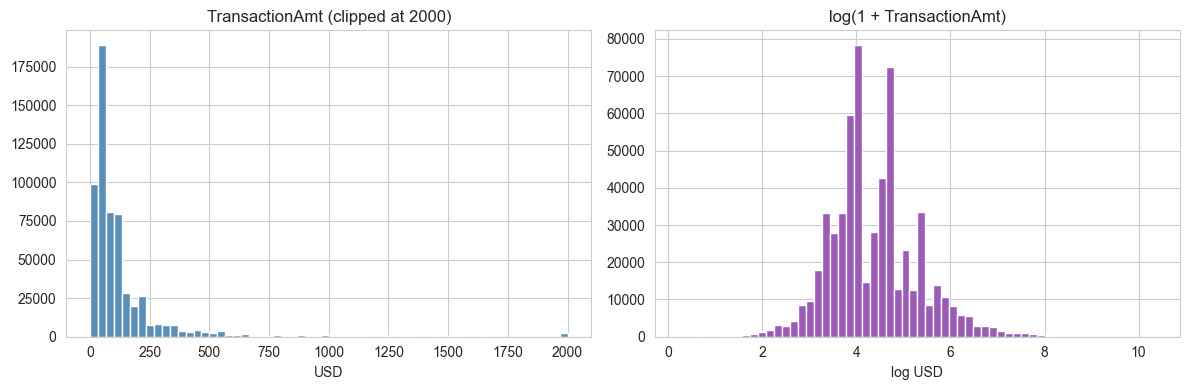

Max amount: 31,937


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["TransactionAmt"].clip(upper=2000).hist(bins=60, ax=ax[0], color="#5B8FB9")
ax[0].set_title("TransactionAmt (clipped at 2000)"); ax[0].set_xlabel("USD")
np.log1p(df["TransactionAmt"]).hist(bins=60, ax=ax[1], color="#9D5BB9")
ax[1].set_title("log(1 + TransactionAmt)"); ax[1].set_xlabel("log USD")
plt.tight_layout(); plt.show()
print(f"Max amount: {df['TransactionAmt'].max():,.0f}")

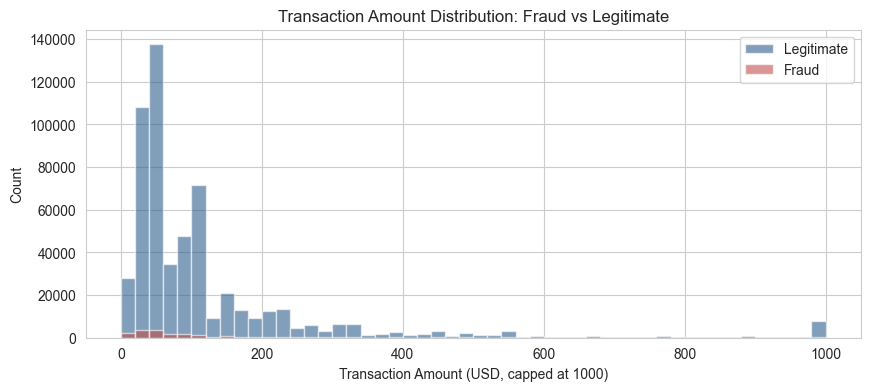

Max amount: 31,937


In [13]:
# Transaction amount: fraud vs legitimate
plt.figure(figsize=(10, 4))
plt.hist(df[df['isFraud']==0]['TransactionAmt'].clip(upper=1000),
         bins=50, alpha=0.6, label='Legitimate', color='#2E5E8C')
plt.hist(df[df['isFraud']==1]['TransactionAmt'].clip(upper=1000),
         bins=50, alpha=0.6, label='Fraud', color='#C0504D')
plt.xlabel('Transaction Amount (USD, capped at 1000)')
plt.ylabel('Count')
plt.title('Transaction Amount Distribution: Fraud vs Legitimate')
plt.legend()
plt.show()
print(f"Max amount: {df['TransactionAmt'].max():,.0f}")

### 2.4 Time features for EDA
`TransactionDT` is seconds from a reference time. We derive **hour** and **day-of-week**
(cheap, deterministic, and the article showed fraud varies with both).

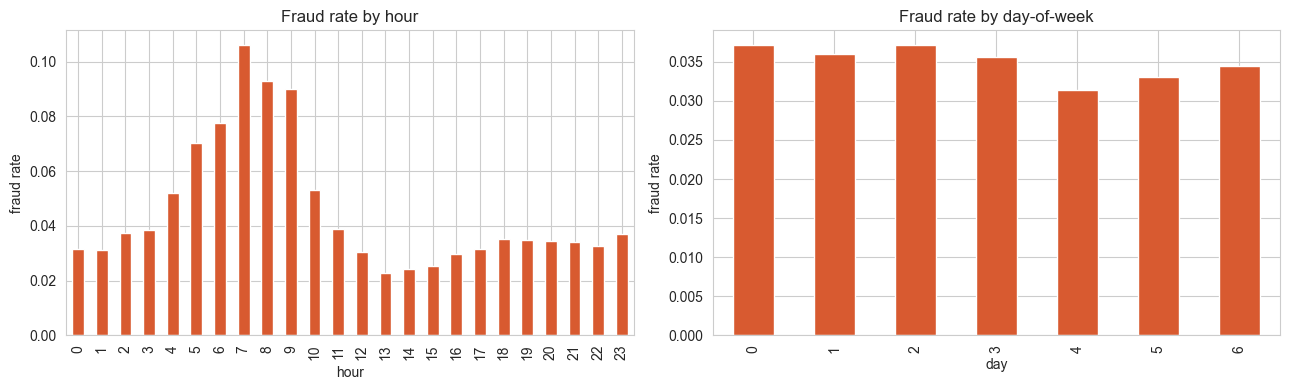

In [15]:
df["hour"] = ((df["TransactionDT"] / 3600) % 24).astype(int)
df["day"]  = ((df["TransactionDT"] / (3600 * 24)) % 7).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df.groupby("hour")["isFraud"].mean().plot(kind="bar", ax=ax[0], color="#D85A30")
ax[0].set_title("Fraud rate by hour"); ax[0].set_ylabel("fraud rate")
df.groupby("day")["isFraud"].mean().plot(kind="bar", ax=ax[1], color="#D85A30")
ax[1].set_title("Fraud rate by day-of-week"); ax[1].set_ylabel("fraud rate")
plt.tight_layout(); plt.show()

   hour  day_of_week  is_night  is_weekend
0     0            1         1           0
1     0            1         1           0
2     0            1         1           0
3     0            1         1           0
4     0            1         1           0


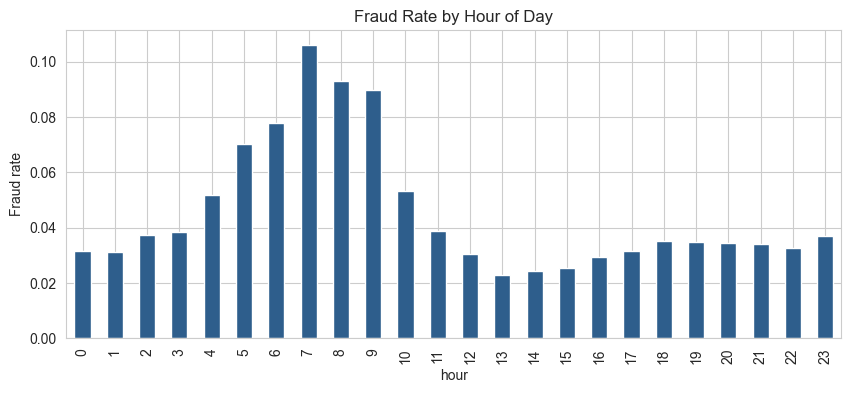

In [22]:
df['hour']        = (df['TransactionDT'] // 3600) % 24
df['day_of_week']  = (df['TransactionDT'] // (3600 * 24)) % 7
df['is_night']     = ((df['hour'] >= 22) | (df['hour'] <= 6)).astype('int32')
df['is_weekend']   = (df['day_of_week'] >= 5).astype('int32')

print(df[['hour', 'day_of_week', 'is_night', 'is_weekend']].head())

# Quick check: does fraud rate change by hour?
plt.figure(figsize=(10, 4))
df.groupby('hour')['isFraud'].mean().plot(kind='bar', color='#2E5E8C')
plt.ylabel('Fraud rate')
plt.title('Fraud Rate by Hour of Day')
plt.show()

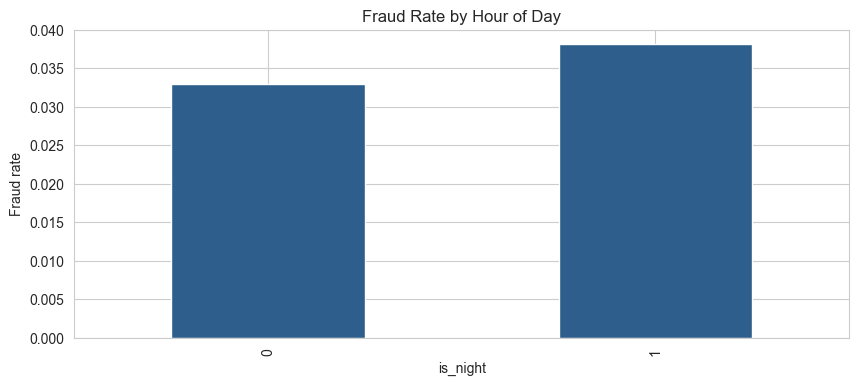

In [23]:
plt.figure(figsize=(10, 4))
df.groupby('is_night')['isFraud'].mean().plot(kind='bar', color='#2E5E8C')
plt.ylabel('Fraud rate')
plt.title('Fraud Rate by Hour of Day')
plt.show()

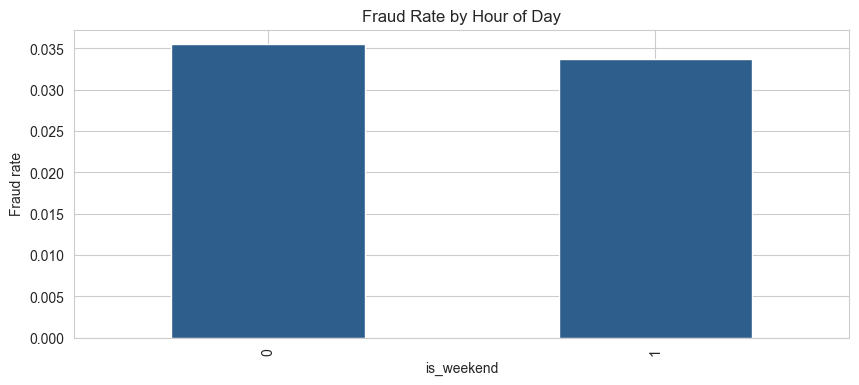

In [24]:
plt.figure(figsize=(10, 4))
df.groupby('is_weekend')['isFraud'].mean().plot(kind='bar', color='#2E5E8C')
plt.ylabel('Fraud rate')
plt.title('Fraud Rate by Hour of Day')
plt.show()

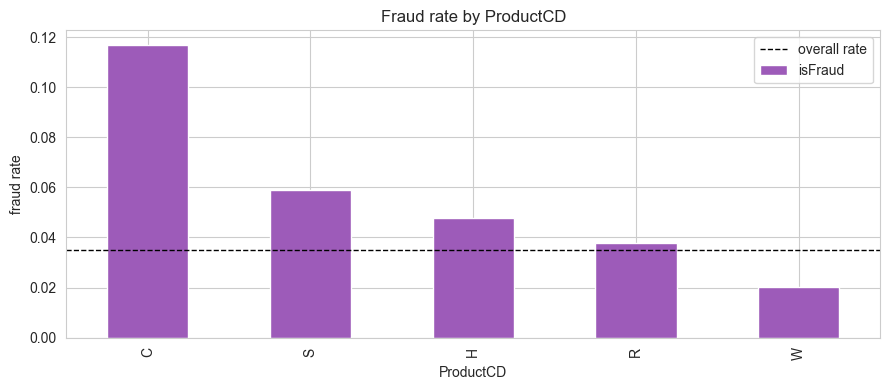

In [25]:
order = df.groupby("ProductCD")["isFraud"].mean().sort_values(ascending=False)
ax = order.plot(kind="bar", color="#9D5BB9")
ax.set_title("Fraud rate by ProductCD"); ax.set_ylabel("fraud rate")
plt.axhline(df["isFraud"].mean(), color="black", ls="--", lw=1, label="overall rate")
plt.legend(); plt.tight_layout(); plt.show()

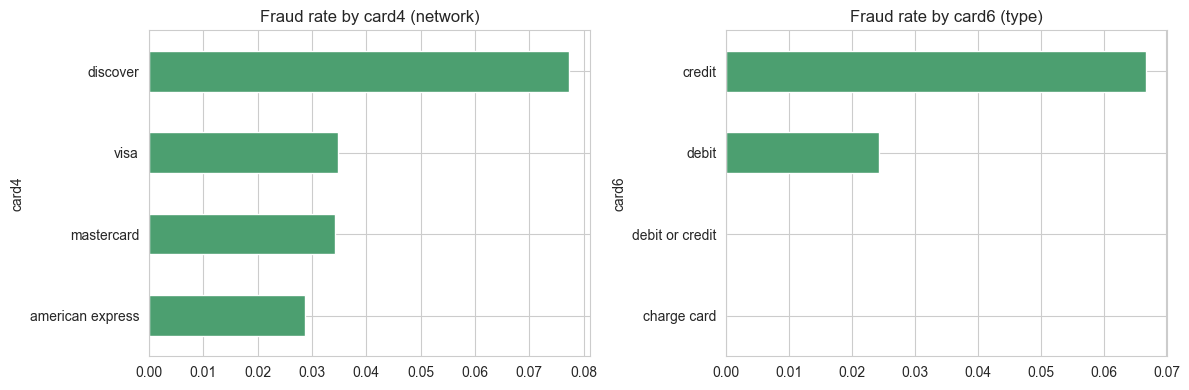

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("card4")["isFraud"].mean().sort_values().plot(kind="barh", ax=ax[0], color="#4C9F70")
ax[0].set_title("Fraud rate by card4 (network)")
df.groupby("card6")["isFraud"].mean().sort_values().plot(kind="barh", ax=ax[1], color="#4C9F70")
ax[1].set_title("Fraud rate by card6 (type)")
plt.tight_layout(); plt.show()

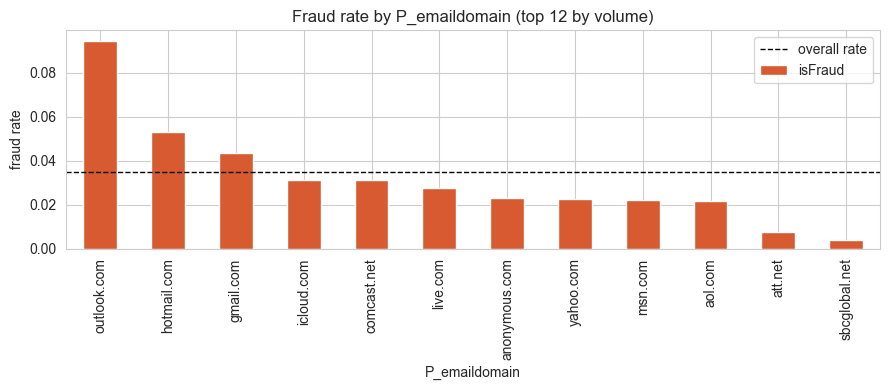

In [27]:
top_dom = df["P_emaildomain"].value_counts().head(12).index
sub = df[df["P_emaildomain"].isin(top_dom)]
order = sub.groupby("P_emaildomain")["isFraud"].mean().sort_values(ascending=False)
ax = order.plot(kind="bar", color="#D85A30")
ax.set_title("Fraud rate by P_emaildomain (top 12 by volume)"); ax.set_ylabel("fraud rate")
plt.axhline(df["isFraud"].mean(), color="black", ls="--", lw=1, label="overall rate")
plt.legend(); plt.tight_layout(); plt.show()

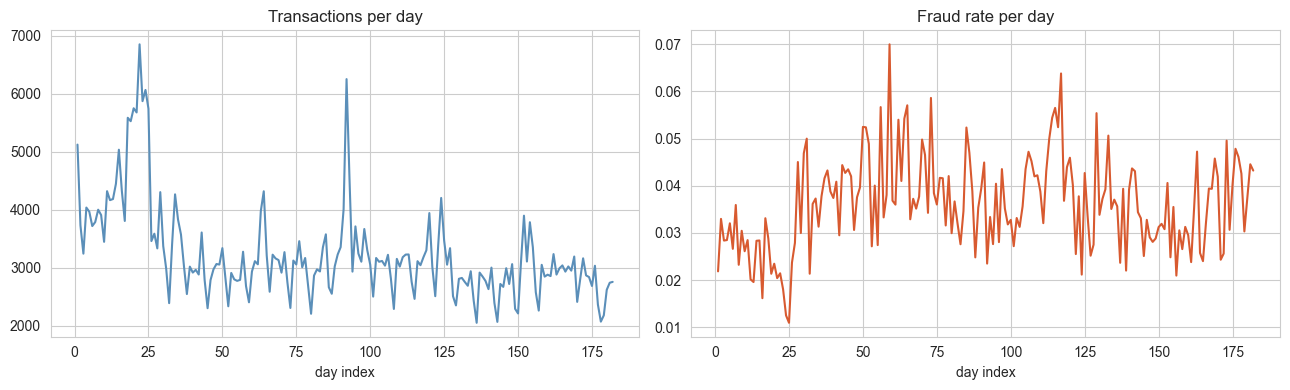

In [28]:
day = (df["TransactionDT"] / (3600 * 24)).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
day.value_counts().sort_index().plot(ax=ax[0], color="#5B8FB9")
ax[0].set_title("Transactions per day"); ax[0].set_xlabel("day index")
df.assign(day=day).groupby("day")["isFraud"].mean().plot(ax=ax[1], color="#D85A30")
ax[1].set_title("Fraud rate per day"); ax[1].set_xlabel("day index")
plt.tight_layout(); plt.show()

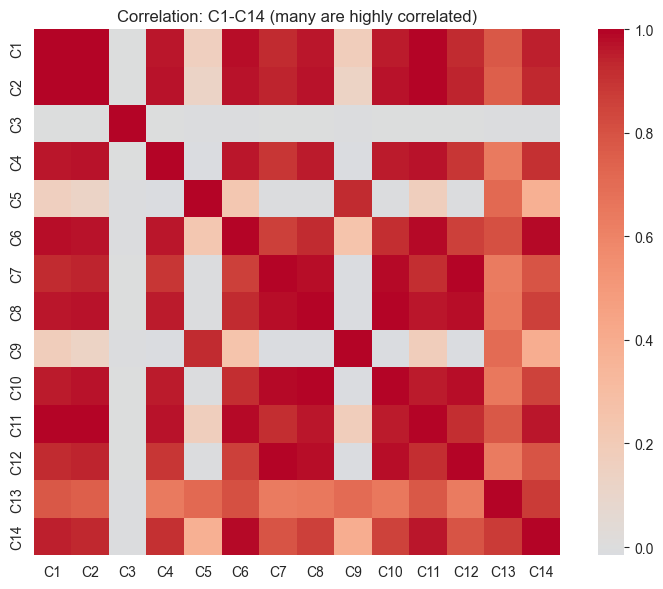

In [29]:
c_cols = [c for c in df.columns if c.startswith("C") and c[1:].isdigit()]
plt.figure(figsize=(8, 6))
sns.heatmap(df[c_cols].corr(), cmap="coolwarm", center=0, square=True)
plt.title("Correlation: C1-C14 (many are highly correlated)")
plt.tight_layout(); plt.show()

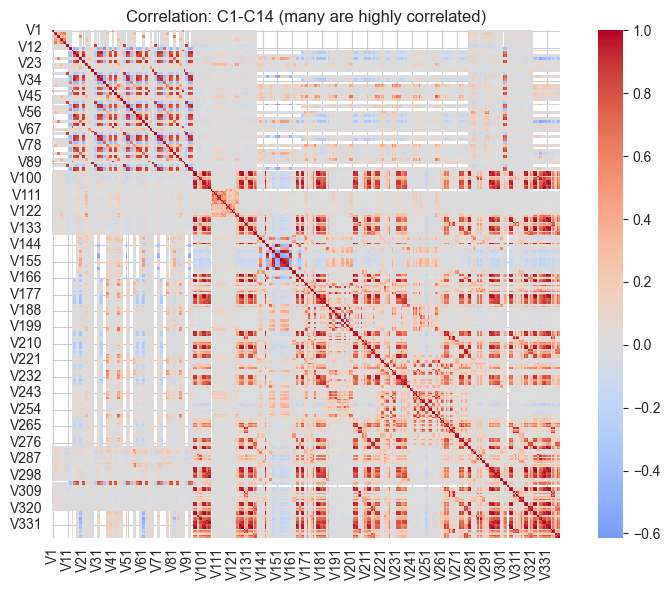

In [ ]:
c_cols = [c for c in df.columns if c.startswith("V") and c[1:].isdigit()]
plt.figure(figsize=(8, 6))
sns.heatmap(df[c_cols].corr(), cmap="coolwarm", center=0, square=True)
plt.title("Correlation: V1-V331 (many are highly correlated)")
plt.tight_layout(); plt.show()

In [30]:
tx  = pd.read_csv('C:\\Users\\admin\\Desktop\\M2 thesis\\ieee-fraud-detection\\train_transaction.csv')
idn = pd.read_csv('C:\\Users\\admin\\Desktop\\M2 thesis\\ieee-fraud-detection\\train_identity.csv')
train = tx.merge(idn, how="left", on="TransactionID")
del tx, idn
print(f"Merged train shape: {train.shape[0]:,} rows x {train.shape[1]} columns")

tx_test  = pd.read_csv('C:\\Users\\admin\\Desktop\\M2 thesis\\ieee-fraud-detection\\test_transaction.csv')
idn_test = pd.read_csv('C:\\Users\\admin\\Desktop\\M2 thesis\\ieee-fraud-detection\\test_identity.csv')
test = tx_test.merge(idn_test, how="left", on="TransactionID")
del tx_test, idn_test
print(f"Merged test shape: {test.shape[0]:,} rows x {test.shape[1]} columns")

Merged train shape: 590,540 rows x 434 columns
Merged test shape: 506,691 rows x 433 columns


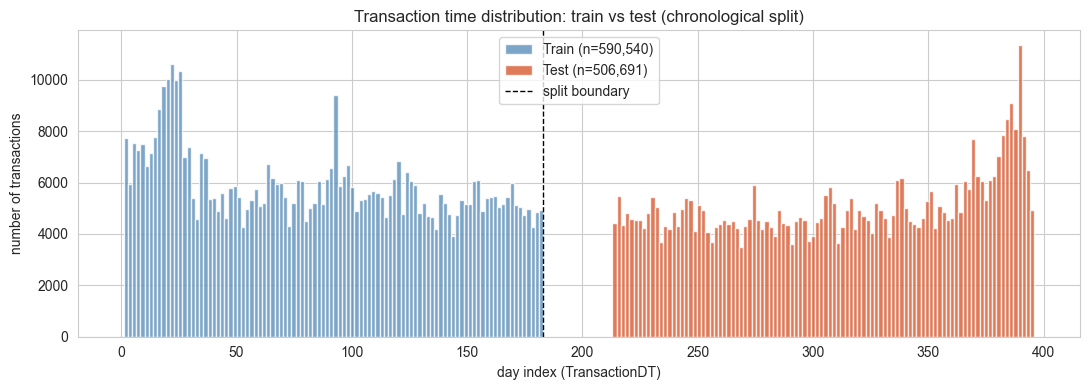

In [31]:
import matplotlib.pyplot as plt

# train, test already created by the chronological split
plt.figure(figsize=(11, 4))
bins = 100
plt.hist(train["TransactionDT"] / (3600*24), bins=bins, color="#5B8FB9",
         alpha=0.8, label=f"Train (n={len(train):,})")
plt.hist(test["TransactionDT"]  / (3600*24), bins=bins, color="#D85A30",
         alpha=0.8, label=f"Test (n={len(test):,})")
plt.axvline(train["TransactionDT"].max() / (3600*24), color="black", ls="--", lw=1,
            label="split boundary")
plt.xlabel("day index (TransactionDT)")
plt.ylabel("number of transactions")
plt.title("Transaction time distribution: train vs test (chronological split)")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
df = df.sort_values("TransactionDT").reset_index(drop=True)
cut = int(len(df) * 0.80)
train = df.iloc[:cut].copy()
test  = df.iloc[cut:].copy()
del df
print(f"Train: {train.shape[0]:,} rows  (fraud {train['isFraud'].mean():.2%})")
print(f"Test : {test.shape[0]:,} rows  (fraud {test['isFraud'].mean():.2%})")

Train: 472,429 rows  (fraud 3.51%)
Test : 118,108 rows  (fraud 3.44%)


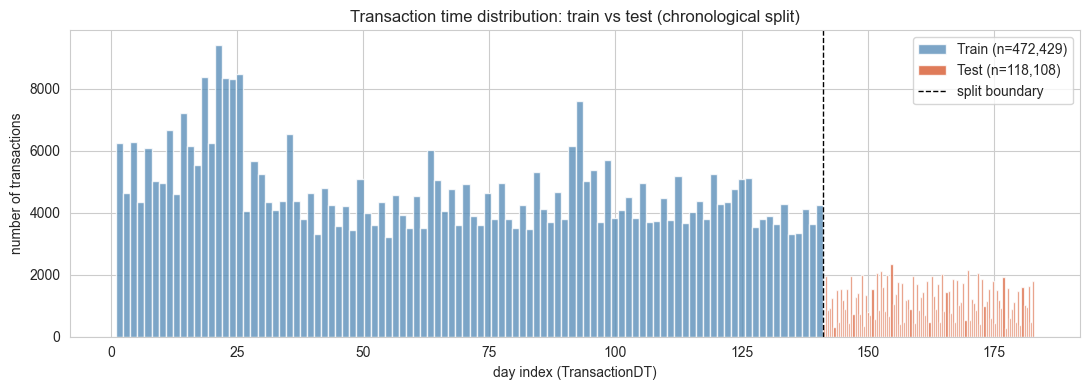

In [19]:
import matplotlib.pyplot as plt

# train, test already created by the chronological split
plt.figure(figsize=(11, 4))
bins = 100
plt.hist(train["TransactionDT"] / (3600*24), bins=bins, color="#5B8FB9",
         alpha=0.8, label=f"Train (n={len(train):,})")
plt.hist(test["TransactionDT"]  / (3600*24), bins=bins, color="#D85A30",
         alpha=0.8, label=f"Test (n={len(test):,})")
plt.axvline(train["TransactionDT"].max() / (3600*24), color="black", ls="--", lw=1,
            label="split boundary")
plt.xlabel("day index (TransactionDT)")
plt.ylabel("number of transactions")
plt.title("Transaction time distribution: train vs test (chronological split)")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TRAIN_C, TEST_C = "#4C72B0", "#C44E52"   # train = blue, test = red

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})

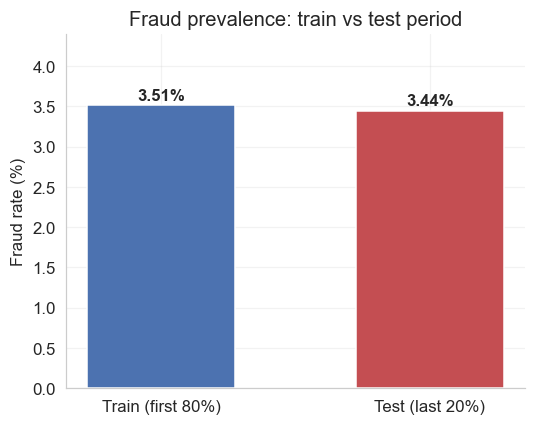

Train fraud rate : 3.514%
Test  fraud rate : 3.441%
Relative change  : -2.1% (test vs train)
Each rate is the AUC-PR no-skill baseline for that split — a model is only
useful if its test AUC-PR clears the test-period rate shown above.


In [21]:
tr_rate, te_rate = train["isFraud"].mean(), test["isFraud"].mean()

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Train (first 80%)", "Test (last 20%)"],
              [tr_rate*100, te_rate*100], color=[TRAIN_C, TEST_C], width=0.55)
for b, r in zip(bars, [tr_rate, te_rate]):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.03,
            f"{r:.2%}", ha="center", va="bottom", fontweight="bold")
ax.set_ylabel("Fraud rate (%)"); ax.set_title("Fraud prevalence: train vs test period")
ax.set_ylim(0, max(tr_rate, te_rate)*100*1.25)
plt.tight_layout(); plt.show()

print(f"Train fraud rate : {tr_rate:.3%}")
print(f"Test  fraud rate : {te_rate:.3%}")
print(f"Relative change  : {(te_rate/tr_rate - 1):+.1%} (test vs train)")
print("Each rate is the AUC-PR no-skill baseline for that split — a model is only")
print("useful if its test AUC-PR clears the test-period rate shown above.")

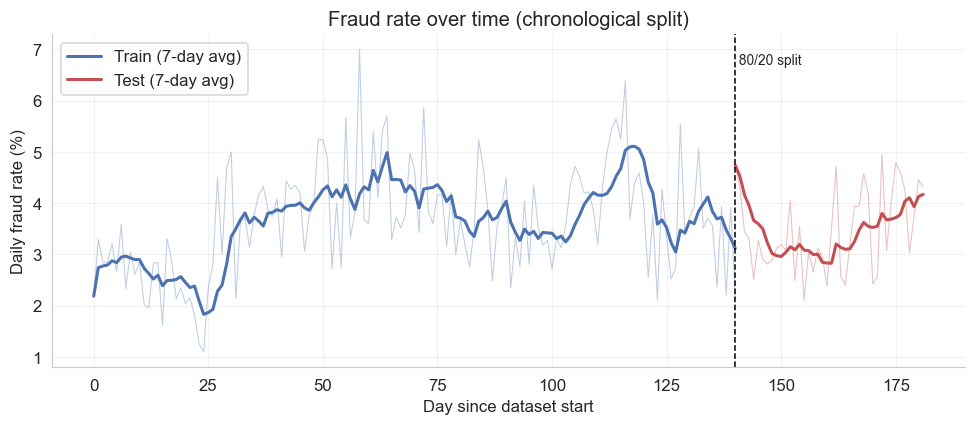

Shows whether fraud prevalence drifts across the timeline. Divergence after
the dashed line is direct visual evidence of temporal shift into the test period.


In [22]:
def daily_rate(dt, y, ref):
    d = ((dt - ref) // 86400).astype(int)
    return pd.DataFrame({"day": d, "f": y.values}).groupby("day")["f"].mean()

ref = train["TransactionDT"].min()
gt = daily_rate(train["TransactionDT"], train["isFraud"], ref)
ge = daily_rate(test["TransactionDT"],  test["isFraud"],  ref)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(gt.index, gt.values*100, color=TRAIN_C, lw=0.7, alpha=0.35)
ax.plot(gt.index, gt.rolling(7, min_periods=1).mean()*100, color=TRAIN_C, lw=2, label="Train (7-day avg)")
ax.plot(ge.index, ge.values*100, color=TEST_C, lw=0.7, alpha=0.35)
ax.plot(ge.index, ge.rolling(7, min_periods=1).mean()*100, color=TEST_C, lw=2, label="Test (7-day avg)")
cut_day = gt.index.max()
ax.axvline(cut_day, color="k", ls="--", lw=1)
ax.text(cut_day, ax.get_ylim()[1]*0.95, " 80/20 split", va="top", fontsize=9)
ax.set_xlabel("Day since dataset start"); ax.set_ylabel("Daily fraud rate (%)")
ax.set_title("Fraud rate over time (chronological split)"); ax.legend()
plt.tight_layout(); plt.show()
print("Shows whether fraud prevalence drifts across the timeline. Divergence after")
print("the dashed line is direct visual evidence of temporal shift into the test period.")

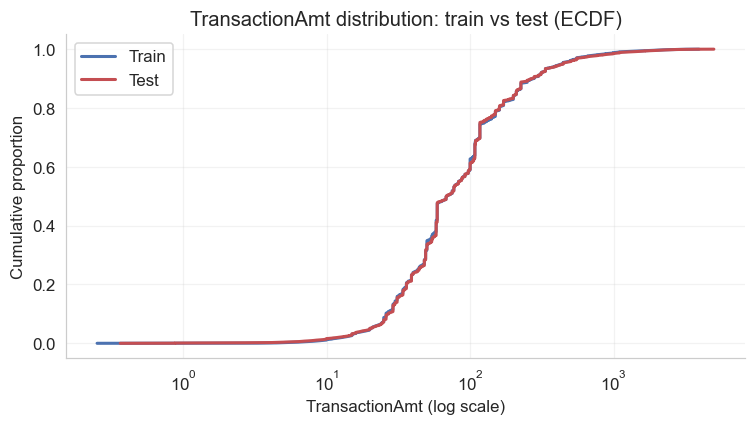

           Train       Test
count  472429.00  118108.00
mean      134.40     137.53
std       237.56     245.46
min         0.25       0.36
25%        42.95      44.00
50%        68.95      68.50
75%       125.00     117.00
90%       277.00     269.95
99%      1104.00    1222.00
max     31937.39    5366.82

Overlapping curves = stable spending distribution; horizontal separation = amount drift.


In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, part, c in [("Train", train, TRAIN_C), ("Test", test, TEST_C)]:
    x = np.sort(part["TransactionAmt"].values)
    y = np.arange(1, len(x)+1) / len(x)
    step = max(1, len(x)//5000)          # thin for a fast, smooth line
    ax.plot(x[::step], y[::step], color=c, lw=2, label=name)
ax.set_xscale("log"); ax.set_xlabel("TransactionAmt (log scale)")
ax.set_ylabel("Cumulative proportion")
ax.set_title("TransactionAmt distribution: train vs test (ECDF)"); ax.legend()
plt.tight_layout(); plt.show()

summ = pd.DataFrame({"Train": train["TransactionAmt"].describe([.25,.5,.75,.9,.99]),
                     "Test":  test["TransactionAmt"].describe([.25,.5,.75,.9,.99])})
print(summ.round(2))
print("\nOverlapping curves = stable spending distribution; horizontal separation = amount drift.")

## 3. Chronological split - the leakage boundary

Sort by time, take the first 80% as **train** (past) and the last 20% as **test** (future).
Everything after this point is learned on train only.

In [ ]:
df = df.sort_values("TransactionDT").reset_index(drop=True)
cut = int(len(df) * 0.80)
train = df.iloc[:cut].copy()
test  = df.iloc[cut:].copy()
del df
print(f"Train: {train.shape[0]:,} rows  (fraud {train['isFraud'].mean():.2%})")
print(f"Test : {test.shape[0]:,} rows  (fraud {test['isFraud'].mean():.2%})")

In [ ]:
# Sort by time
df = df.sort_values('TransactionDT').reset_index(drop=True)

split_idx = int(len(df) * 0.80)
train = df.iloc[:split_idx]
test  = df.iloc[split_idx:]

print(f'Train: {train.shape}  | fraud rate {train["isFraud"].mean()*100:.2f}%')
print(f'Test:  {test.shape}   | fraud rate {test["isFraud"].mean()*100:.2f}%')

# Separate features (X) and target (y); drop ID and target from X
drop_cols = ['isFraud', 'TransactionID']
X_train = train.drop(columns=drop_cols)
y_train = train['isFraud']
X_test  = test.drop(columns=drop_cols)
y_test  = test['isFraud']

print('\nX_train:', X_train.shape, '| X_test:', X_test.shape)

## 6. Encode ALL categoricals - fixes the `'W'` error permanently

Label-encode every text column, **fitting the mapping on train**. Values that appear only in
test (unseen) get `-1`. After this cell, **no column is text**, so MI / models won't crash.

In [ ]:
from sklearn.preprocessing import LabelEncoder

for c in obj_cols:
    le = LabelEncoder()
    le.fit(train[c])
    mapping = {label: i for i, label in enumerate(le.classes_)}
    train[c] = train[c].map(mapping).astype(np.int32)
    test[c]  = test[c].map(mapping).fillna(-1).astype(np.int32)  # unseen -> -1

print("Remaining text columns in train:", [c for c in train.columns if train[c].dtype == 'object'])
print("Remaining text columns in test :", [c for c in test.columns  if test[c].dtype  == 'object'])

In [ ]:
for d in [train, test]:
    d.drop(columns=["TransactionID"], inplace=True, errors="ignore")

assert not any(train[c].dtype == "object" for c in train.columns), "text col left!"
assert train.isna().sum().sum() == 0, "NaNs left in train!"
assert test.isna().sum().sum() == 0, "NaNs left in test!"

print(f"Final train: {train.shape[0]:,} x {train.shape[1]}")
print(f"Final test : {test.shape[0]:,} x {test.shape[1]}")

train.to_parquet("train_preprocessed.parquet", index=False)
test.to_parquet("test_preprocessed.parquet", index=False)
print("Saved: train_preprocessed.parquet, test_preprocessed.parquet")

In [ ]:
X_train.to_parquet(DATA_PATH + 'X_train.parquet')
X_test.to_parquet(DATA_PATH + 'X_test.parquet')
y_train.to_frame().to_parquet(DATA_PATH + 'y_train.parquet')
y_test.to_frame().to_parquet(DATA_PATH + 'y_test.parquet')

# Save feature names for later reference
pd.Series(X_train.columns).to_csv(DATA_PATH + 'feature_names.csv', index=False)

print('Saved:')
print('  X_train.parquet', X_train.shape)
print('  X_test.parquet ', X_test.shape)
print('  y_train.parquet', y_train.shape)
print('  y_test.parquet ', y_test.shape)
print('  feature_names.csv')
print('\n=== PREPROCESSING COMPLETE ===')